# Project 2 - Strategy Construction

This notebook converts research signals into trading rules.

We will build three strategies in separate blocks:
1. volatility timing,
2. pairs trading,
3. regime switching.

Now performance metrics matter, so we will compute returns, equity curves, turnover, and costs.

In [67]:
from pathlib import Path  # Work with repository paths safely.
import sys  # Let us modify the import path for notebook execution.

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()  # Find the repository root.

if str(project_root) not in sys.path:  # Only append the path once.
    sys.path.append(str(project_root))  # Make src/ importable from the notebook.

# Load IPython autoreload so edits in src/ are picked up after rerunning cells.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [68]:
import matplotlib.pyplot as plt  # Plot equity and drawdown curves.
import pandas as pd  # Assemble result tables.

from src.backtest.engine import drawdown_curve, equity_curve, performance_metrics, positions_to_strategy_returns  # Core backtest helpers.
from src.models.ou import compute_spread_zscore  # Standardize the pair spread for entry and exit rules.
from src.models.regime import build_regime_features, fit_hmm_regime_model, infer_regimes  # Build the regime signal.
from src.models.volatility import fit_random_forest_volatility_model, predict_random_forest_volatility, split_train_test  # Build the volatility timing signal.
from src.strategies.pairs_trading import pairs_positions_from_zscore  # Translate z-scores into long and short positions.
from src.strategies.regime_switching import map_regimes_to_labels, regime_based_positions  # Translate regimes into exposures.
from src.strategies.volatility_timing import inverse_volatility_position, naive_buy_and_hold  # Translate volatility into position sizes.
from src.utils.config import COST_CONFIG, DATA_CONFIG  # Shared data and cost settings.
from src.utils.data_loader import build_market_data_bundle, build_spread, make_volatility_features  # Shared data preparation helpers.

## Step 1 - Load the same market dataset used in project 1

Using one shared dataset is important because we want the transition from research to trading to be clean and consistent.

In [69]:
market_data = build_market_data_bundle()  # Download prices, returns, and realized volatility.
prices = market_data.prices  # Save the price table under a short name.
returns = market_data.log_returns  # Save the daily log returns.
realized_vol = market_data.realized_volatility  # Save the rolling realized volatility estimates.

benchmark_asset = DATA_CONFIG.benchmark_symbol  # Use SPY as the main traded asset for timing and regime strategies.
benchmark_returns = returns[benchmark_asset]  # Pull out the SPY return stream.
benchmark_realized_vol = realized_vol[benchmark_asset].reindex(benchmark_returns.index)  # Align the SPY volatility series.

## Strategy A - Volatility timing

Idea: take smaller positions when predicted volatility is high and larger positions when predicted volatility is low.

We compare that dynamic rule against a naive always-long benchmark.

In [70]:
volatility_features = make_volatility_features(benchmark_returns, benchmark_realized_vol)  # Build lagged features and the prediction target.
train_features, test_features = split_train_test(volatility_features)  # Keep training and testing separated in time.

rf_model = fit_random_forest_volatility_model(train_features)  # Fit the volatility forecast model on the training sample.
volatility_signal = predict_random_forest_volatility(rf_model, test_features)  # Predict next-period volatility on the test sample.
vol_timing_positions = inverse_volatility_position(volatility_signal, benchmark_asset)  # Turn predicted volatility into a position size.
naive_positions = naive_buy_and_hold(benchmark_returns.reindex(vol_timing_positions.index), benchmark_asset)  # Create the buy-and-hold benchmark over the same dates. ## remove rows that are not in vol_timing_positions
# print(volatility_signal.tail())

In [71]:
vol_timing_backtest = positions_to_strategy_returns(  # Backtest the dynamic volatility-timing strategy.
    vol_timing_positions,
    returns[[benchmark_asset]],
    transaction_cost_bps=COST_CONFIG.transaction_cost_bps,
    slippage_bps=COST_CONFIG.slippage_bps,
)
naive_backtest = positions_to_strategy_returns(  # Backtest the always-long benchmark with the same cost assumptions.
    naive_positions,
    returns[[benchmark_asset]],
    transaction_cost_bps=COST_CONFIG.transaction_cost_bps,
    slippage_bps=COST_CONFIG.slippage_bps,
)

pd.DataFrame({  # Compare the main metrics side by side.
    "Volatility timing": performance_metrics(vol_timing_backtest["net_return"]),
    "Naive buy and hold": performance_metrics(naive_backtest["net_return"]),
})
# print(naive_backtest.tail())

,Volatility timing,Naive buy and hold
sharpe_ratio,1.182419,1.153616
sortino_ratio,1.681870,1.602947
cagr,0.206258,0.196303
max_drawdown,-0.172342,-0.192090
calmar_ratio,1.196795,1.021932
volatility,0.171015,0.167532
var_95,0.017163,0.015736
expected_shortfall_95,0.024209,0.023131


## Strategy B - Pairs trading

Idea: if the spread between two related assets becomes unusually wide, bet that it will move back toward its historical mean.

In [72]:
asset_a, asset_b = DATA_CONFIG.pair_symbols  # Unpack the configured pair.
spread_frame = build_spread(prices[asset_a], prices[asset_b])  # Estimate the hedge ratio and spread.
spread_zscore = compute_spread_zscore(spread_frame["spread"])  # Standardize the spread into a z-score.
pairs_positions = pairs_positions_from_zscore(spread_zscore, asset_a, asset_b)  # Convert the z-score into long and short positions.

pairs_positions.tail()  # Inspect the latest position values.

,EFA,EEM
Date,,
2025-12-23,-1.0,1.0
2025-12-24,-1.0,1.0
2025-12-26,0.0,-0.0
2025-12-29,0.0,-0.0
2025-12-30,0.0,-0.0


In [73]:
pairs_backtest = positions_to_strategy_returns(  # Backtest the pair with transaction costs included.
    pairs_positions,
    returns[[asset_a, asset_b]],
    transaction_cost_bps=COST_CONFIG.transaction_cost_bps,
    slippage_bps=COST_CONFIG.slippage_bps,
)

pd.Series(performance_metrics(pairs_backtest["net_return"]), name="Pairs trading").to_frame()  # Show the key performance metrics.

,Pairs trading
sharpe_ratio,-0.226183
sortino_ratio,-0.264779
cagr,-0.022718
max_drawdown,-0.307004
calmar_ratio,-0.073998
volatility,0.085454
var_95,0.008777
expected_shortfall_95,0.013268


## Strategy C - Regime switching

Idea: when the market looks like a strong regime, stay invested; when it looks stressed, scale down or step aside.

In [74]:
regime_features = build_regime_features(benchmark_returns, benchmark_realized_vol)  # Build the HMM feature matrix.
hmm_model = fit_hmm_regime_model(regime_features)  # Fit the Hidden Markov Model.
regimes = infer_regimes(hmm_model, regime_features)  # Infer one latent state per date.
regime_table = map_regimes_to_labels(regimes, benchmark_returns)  # Interpret the raw states using their average return.
regime_positions = regime_based_positions(regime_table["regime_label"], benchmark_asset)  # Convert labels into tradable weights.

In [75]:
regime_backtest = positions_to_strategy_returns(  # Backtest the regime-switching strategy.
    regime_positions,
    returns[[benchmark_asset]],
    transaction_cost_bps=COST_CONFIG.transaction_cost_bps,
    slippage_bps=COST_CONFIG.slippage_bps,
)

pd.Series(performance_metrics(regime_backtest["net_return"]), name="Regime switching").to_frame()  # Show the key performance metrics.

,Regime switching
sharpe_ratio,0.887733
sortino_ratio,0.998808
cagr,0.068772
max_drawdown,-0.111475
calmar_ratio,0.616926
volatility,0.078404
var_95,0.007484
expected_shortfall_95,0.012713


In [76]:
strategy_returns = pd.DataFrame({  # Collect the three stage-two strategies in one table.
    "volatility_timing": vol_timing_backtest["net_return"],
    "pairs_trading": pairs_backtest["net_return"],
    "regime_switching": regime_backtest["net_return"],
}).dropna(how="any")

strategy_metrics = pd.DataFrame(
    {name: performance_metrics(strategy_returns[name]) for name in strategy_returns.columns},
)
strategy_metrics.index.name = "metric"

# print(strategy_metrics.to_string())  # plain text
strategy_metrics   # HTML table (preferred in notebooks)

,volatility_timing,pairs_trading,regime_switching
metric,,,
sharpe_ratio,1.182419,-0.335539,1.212675
sortino_ratio,1.681870,-0.356779,1.411120
cagr,0.206258,-0.029546,0.093321
max_drawdown,-0.172342,-0.165263,-0.074387
calmar_ratio,1.196795,-0.178782,1.254540
volatility,0.171015,0.079860,0.075968
var_95,0.017163,0.007874,0.006655
expected_shortfall_95,0.024209,0.013161,0.011708


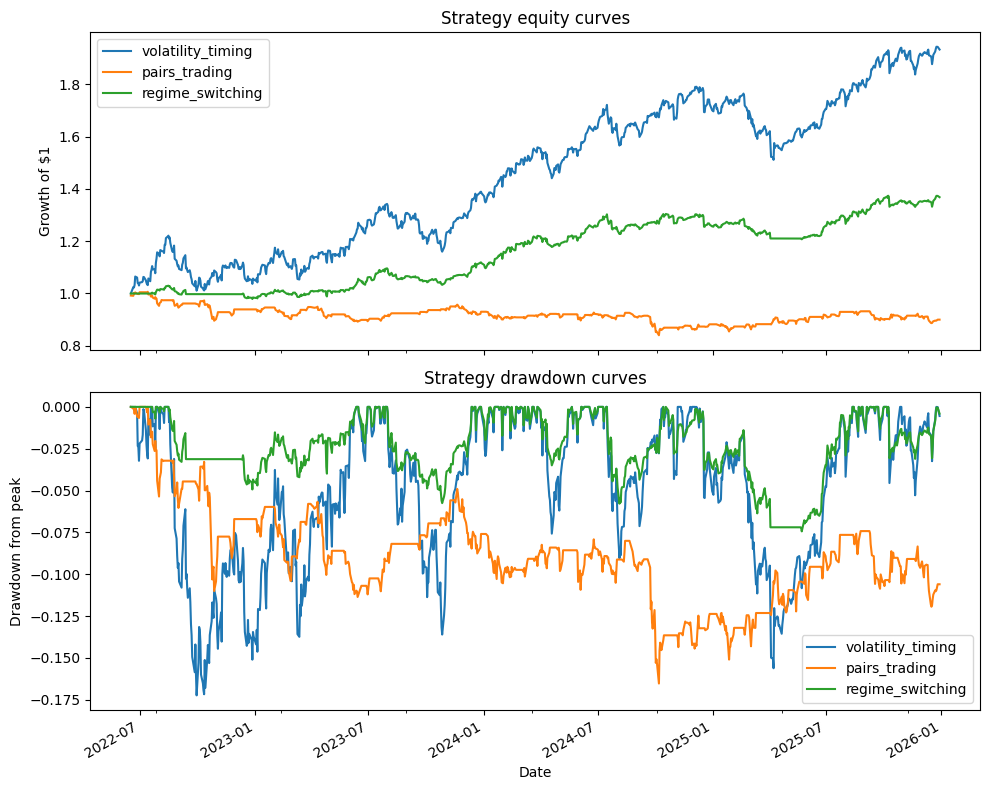

In [77]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)  # Create one panel for equity and one for drawdown.
strategy_returns.apply(equity_curve).plot(ax=axes[0], title="Strategy equity curves")  # Plot cumulative growth for each strategy.
axes[0].set_ylabel("Growth of $1")  # equity_curve compounds from 1.0

strategy_returns.apply(lambda column: drawdown_curve(equity_curve(column))).plot(
    ax=axes[1], title="Strategy drawdown curves"
)  # Plot the percentage loss from peak for each strategy.
axes[1].set_ylabel("Drawdown from peak")
axes[1].set_xlabel("Date")

plt.tight_layout()  # Reduce overlap between the two panels.
plt.show()  # Render the figure.

## Walk-forward out-of-sample validation

The blocks above fit each model **once** on all available history (volatility timing already uses a single **train/test** split for the random forest, but the HMM and pair hedge are full-sample). Here we add an **expanding walk-forward**: on each fold we refit on all data up to a boundary, trade only the **next** non-overlapping test window, then move the boundary forward. Regime **bull/sideways/crisis** labels use **train-window returns only**, then the same map is applied to decoded test states. Pair **hedge ratios** are re-estimated the same way. Metrics below use the **intersection** of the three walk-forward return series (`dropna(how="any")`) so Sharpe/CAGR are comparable **on identical dates**.

In [78]:
from src.backtest.walk_forward import (
    walk_forward_pairs_positions,
    walk_forward_regime_positions,
    walk_forward_volatility_positions,
)

wf_min_train = max(DATA_CONFIG.annualization_factor * 2, len(volatility_features.index) // 5)
wf_test = DATA_CONFIG.rolling_vol_window

vol_timing_wf_positions = walk_forward_volatility_positions(
    volatility_features,
    benchmark_asset,
    min_train_observations=wf_min_train,
    test_observations=wf_test,
)
regime_wf_positions = walk_forward_regime_positions(
    regime_features,
    benchmark_returns,
    benchmark_asset,
    min_train_observations=wf_min_train,
    test_observations=wf_test,
)
pairs_wf_positions = walk_forward_pairs_positions(
    prices[asset_a],
    prices[asset_b],
    asset_a,
    asset_b,
    min_train_observations=wf_min_train,
    test_observations=wf_test,
    zscore_window=DATA_CONFIG.rolling_vol_window,
)
print(vol_timing_wf_positions.tail())

                 SPY
Date                
2025-12-05  0.812352
2025-12-08  0.841989
2025-12-09  0.842045
2025-12-10  0.920753
2025-12-11  0.920784


In [79]:
vol_timing_wf_bt = positions_to_strategy_returns(
    vol_timing_wf_positions,
    returns[[benchmark_asset]],
    transaction_cost_bps=COST_CONFIG.transaction_cost_bps,
    slippage_bps=COST_CONFIG.slippage_bps,
)
regime_wf_bt = positions_to_strategy_returns(
    regime_wf_positions,
    returns[[benchmark_asset]],
    transaction_cost_bps=COST_CONFIG.transaction_cost_bps,
    slippage_bps=COST_CONFIG.slippage_bps,
)
pairs_wf_bt = positions_to_strategy_returns(
    pairs_wf_positions,
    returns[[asset_a, asset_b]],
    transaction_cost_bps=COST_CONFIG.transaction_cost_bps,
    slippage_bps=COST_CONFIG.slippage_bps,
)
print(vol_timing_wf_bt.tail())

            gross_return  turnover     cost_rate  net_return
Date                                                        
2025-12-05      0.001538  0.001813  1.269106e-06    0.001537
2025-12-08     -0.002444  0.029637  2.074563e-05   -0.002465
2025-12-09     -0.000727  0.000057  3.963271e-08   -0.000727
2025-12-10      0.005566  0.078708  5.509544e-05    0.005511
2025-12-11      0.002140  0.000031  2.171706e-08    0.002140


In [80]:

strategy_returns_wf = pd.DataFrame(
    {
        "volatility_timing_wf": vol_timing_wf_bt["net_return"],
        "pairs_trading_wf": pairs_wf_bt["net_return"],
        "regime_switching_wf": regime_wf_bt["net_return"],
    }
).dropna(how="any")

strategy_metrics_wf = pd.DataFrame(
    {name: performance_metrics(strategy_returns_wf[name]) for name in strategy_returns_wf.columns},
)
strategy_metrics_wf.index.name = "metric"
strategy_metrics_wf

,volatility_timing_wf,pairs_trading_wf,regime_switching_wf
metric,,,
sharpe_ratio,0.917678,-0.240895,0.828427
sortino_ratio,1.129788,-0.273847,0.898617
cagr,0.099886,-0.024982,0.059917
max_drawdown,-0.152616,-0.289890,-0.115994
calmar_ratio,0.654490,-0.086178,0.516558
volatility,0.110433,0.088688,0.073524
var_95,0.010850,0.009538,0.006774
expected_shortfall_95,0.017638,0.014286,0.011820


In [81]:
# Side by side on the merged walk-forward calendar: static full-sample rules (without walk-forward OOS) vs refit walk-forward paths (with OOS).
wf_compare_dates = strategy_returns_wf.index

naive_wf_positions = naive_buy_and_hold(
    benchmark_returns.reindex(wf_compare_dates),
    benchmark_asset,
)
naive_wf_bt = positions_to_strategy_returns(
    naive_wf_positions,
    returns[[benchmark_asset]],
    transaction_cost_bps=COST_CONFIG.transaction_cost_bps,
    slippage_bps=COST_CONFIG.slippage_bps,
)

strategy_is_vs_wf_comparison = pd.DataFrame(
    {
        ("Volatility timing", "in-sample"): pd.Series(
            performance_metrics(
                vol_timing_backtest["net_return"].reindex(wf_compare_dates).dropna(),
            ),
        ),
        ("Volatility timing", "OOS"): pd.Series(
            performance_metrics(strategy_returns_wf["volatility_timing_wf"].dropna()),
        ),
        ("Naive buy and hold", "in-sample"): pd.Series(
            performance_metrics(
                naive_backtest["net_return"].reindex(wf_compare_dates).dropna(),
            ),
        ),
        ("Naive buy and hold", "OOS"): pd.Series(
            performance_metrics(naive_wf_bt["net_return"].dropna()),
        ),
        ("Pairs trading", "in-sample"): pd.Series(
            performance_metrics(
                pairs_backtest["net_return"].reindex(wf_compare_dates).dropna(),
            ),
        ),
        ("Pairs trading", "OOS"): pd.Series(
            performance_metrics(strategy_returns_wf["pairs_trading_wf"].dropna()),
        ),
        ("Regime switching", "in-sample"): pd.Series(
            performance_metrics(
                regime_backtest["net_return"].reindex(wf_compare_dates).dropna(),
            ),
        ),
        ("Regime switching", "OOS"): pd.Series(
            performance_metrics(strategy_returns_wf["regime_switching_wf"].dropna()),
        ),
    },
)
strategy_is_vs_wf_comparison.columns.names = ["strategy", "evaluation"]
strategy_is_vs_wf_comparison.index.name = "metric"

from IPython.display import display

display(strategy_is_vs_wf_comparison)

strategy              Volatility timing           Naive buy and hold  \
evaluation                    in-sample       OOS          in-sample   
metric                                                                 
sharpe_ratio                   1.192555  0.917678           1.161883   
sortino_ratio                  1.695184  1.129788           1.613538   
cagr                           0.209042  0.099886           0.198726   
max_drawdown                  -0.172342 -0.152616          -0.192090   
calmar_ratio                   1.212946  0.654490           1.034548   
volatility                     0.171576  0.110433           0.168175   
var_95                         0.017331  0.010850           0.015825   
expected_shortfall_95          0.024367  0.017638           0.023298   

strategy                        Pairs trading           Regime switching  \
evaluation                  OOS     in-sample       OOS        in-sample   
metric                                                                     
sharpe_ratio           0.764353      0.047087 -0.240895         1.081734   
sortino_ratio          0.892476      0.052208 -0.273847         1.206685   
cagr                   0.130612      0.000359 -0.024982         0.084453   
max_drawdown          -0.357459     -0.203155 -0.289890        -0.098368   
calmar_ratio           0.365391      0.001769 -0.086178         0.858539   
volatility             0.182550      0.085815  0.088688         0.077765   
var_95                 0.017104      0.008613  0.009538         0.007162   
expected_shortfall_95  0.028525      0.013602  0.014286         0.012485   

strategy                         
evaluation                  OOS  
metric                           
sharpe_ratio           0.828427  
sortino_ratio          0.898617  
cagr                   0.059917  
max_drawdown          -0.115994  
calmar_ratio           0.516558  
volatility             0.073524  
var_95                 0.006774  
expected_shortfall_95  0.011820

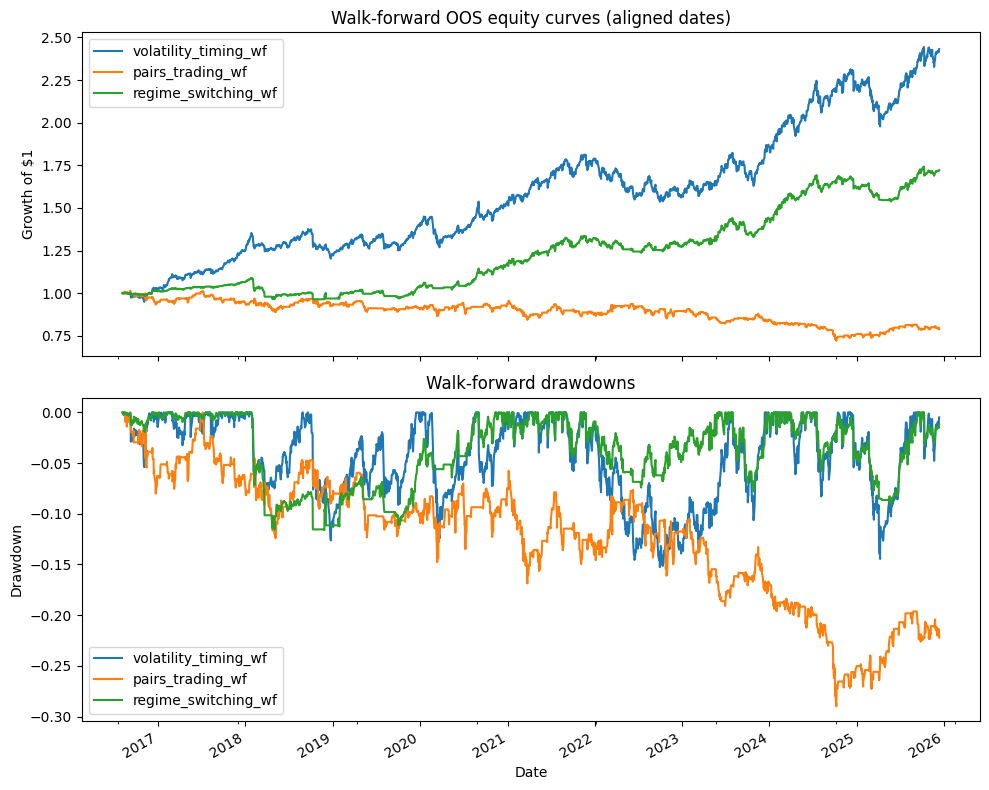

In [82]:
fig_wf, axes_wf = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
strategy_returns_wf.apply(equity_curve).plot(ax=axes_wf[0], title="Walk-forward OOS equity curves (aligned dates)")
axes_wf[0].set_ylabel("Growth of $1")
strategy_returns_wf.apply(lambda column: drawdown_curve(equity_curve(column))).plot(
    ax=axes_wf[1], title="Walk-forward drawdowns"
)
axes_wf[1].set_ylabel("Drawdown")
fig_wf.tight_layout()